# Clasificación de defectos en aisladores eléctricos

**Kimberly Andrada · Diplomado ML/DL FIUNA 2026**


Este notebook documenta el experimento completo de clasificación multietiqueta de recortes de aisladores: rotura (`broken`) y contaminación/flashover (`pollution-flashover`).

El dataset utilizado es Roboflow Insulator Defect v2, con licencia CC BY 4.0.

## 1. Carga y control de datos

In [1]:
from pathlib import Path
import pandas as pd

ruta_csv = Path("data/processed/labels.csv")
datos = pd.read_csv(ruta_csv)

print("Cantidad de recortes:", len(datos))
print("Columnas:", datos.columns.tolist())
display(datos.head())

Cantidad de recortes: 3467
Columnas: ['filename', 'split', 'source_file', 'original_group', 'broken', 'pollution-flashover']


,filename,split,source_file,original_group,broken,pollution-flashover
0,train_0_0.jpg,train,170115v_jpg.rf.c4f1299bb9276f231862e89dbae12c1...,170115,1,0
1,train_0_1.jpg,train,170115v_jpg.rf.c4f1299bb9276f231862e89dbae12c1...,170115,0,0
2,train_107_0.jpg,train,170115v_jpg.rf.cc4993339a303bf8ee67fd378a104cc...,170115,1,0
3,train_107_1.jpg,train,170115v_jpg.rf.cc4993339a303bf8ee67fd378a104cc...,170115,0,0
4,train_397_0.jpg,train,170115d_jpg.rf.e0a74413267e58cadedc7e8dc0af556...,170115,0,0


## División de los datos

Se utilizó una división estratificada por combinación de defectos,
con semilla 42 y proporciones 70/15/15 a nivel de grupo.

Resultaron 280/60/60 grupos y 3324/73/70 recortes para train,
validación y test, respectivamente.

Los grupos se obtienen de los nombres de archivo, eliminando el hash
de Roboflow y los sufijos h, v y d. La comprobación de cero cruces
verifica estos identificadores; no descarta similitudes visuales
entre grupos diferentes.

In [2]:
resumen = datos.groupby("split").agg(
    recortes=("filename", "count"),
    escenas=("original_group", "nunique"),
    con_rotura=("broken", "sum"),
    con_contaminacion=("pollution-flashover", "sum"),
)

display(resumen.reindex(["train", "valid", "test"]))

,recortes,escenas,con_rotura,con_contaminacion
split,,,,
train,3324,280,1448,1483
valid,73,60,29,31
test,70,60,30,31


In [3]:
grupos = {
    split: set(datos.loc[datos["split"] == split, "original_group"])
    for split in ["train", "valid", "test"]
}

for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    compartidos = grupos[a] & grupos[b]
    print(f"{a} / {b}: {len(compartidos)} grupos compartidos")
    assert not compartidos, f"Hay grupos compartidos entre {a} y {b}"

train / valid: 0 grupos compartidos
train / test: 0 grupos compartidos
valid / test: 0 grupos compartidos


In [4]:
combinaciones = (
    datos.groupby(["split", "broken", "pollution-flashover"])
    .size()
    .unstack(["broken", "pollution-flashover"], fill_value=0)
    .reindex(["train", "valid", "test"])
    .reindex(columns=[(0, 0), (1, 0), (0, 1), (1, 1)], fill_value=0)
)

combinaciones.columns = [
    "Sin defectos anotados",
    "Solo rotura",
    "Solo contaminación/flashover",
    "Ambos defectos",
]

display(combinaciones)

,Sin defectos anotados,Solo rotura,Solo contaminación/flashover,Ambos defectos
split,,,,
train,460,1381,1416,67
valid,15,27,29,2
test,10,29,30,1


### Distribución de etiquetas

Rotura y contaminación/flashover no son categorías excluyentes:
un recorte puede presentar ambos defectos.

La combinación de ambos defectos es poco frecuente y solo tiene un ejemplo
en test, lo que limita las conclusiones sobre ese caso.

La etiqueta [0, 0] indica ausencia de estos defectos en las anotaciones;
no garantiza que el aislador esté completamente sano.

## Preprocesamiento de imágenes

Cada recorte se convierte a RGB y se transforma en un tensor de tamaño
3 × 224 × 224. 

Se utiliza la misma transformación durante entrenamiento, evaluación
e inferencia en la aplicación.

In [5]:
from dataset_aisladores import transformacion

print(transformacion)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


El preprocesamiento utiliza Resize para ajustar los recortes a 224 × 224
píxeles, ToTensor para convertirlos a tensores y Normalize con las medias
y desviaciones de ImageNet, correspondientes al modelo preentrenado.

In [6]:
from dataset_aisladores import DatasetAisladores

train = DatasetAisladores(
    "data/processed/labels.csv", "data/processed", "train"
)

valid = DatasetAisladores(
    "data/processed/labels.csv", "data/processed", "valid"
)

test = DatasetAisladores(
    "data/processed/labels.csv", "data/processed", "test"
)

print("Recortes train:", len(train))
print("Recortes valid:", len(valid))
print("Recortes test:", len(test))

imagen, etiquetas = train[0]

print("Forma de una imagen:", imagen.shape)
print("Etiquetas [broken, pollution-flashover]:", etiquetas)

Recortes train: 3324
Recortes valid: 73
Recortes test: 70
Forma de una imagen: torch.Size([3, 224, 224])
Etiquetas [broken, pollution-flashover]: tensor([1., 0.])


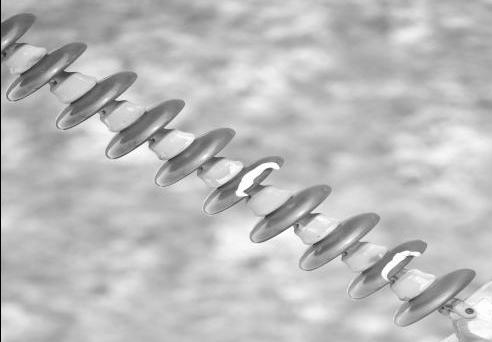

Rotura: 1
Contaminación/flashover: 0


In [ ]:
from PIL import Image
from IPython.display import display

#Vemos un ejemplo de recorte y sus etiquetas

fila = train.tabla.iloc[0]
ruta = train.carpeta_imagenes / fila["filename"]

with Image.open(ruta) as archivo:
    display(archivo.convert("RGB"))

print("Rotura:", fila["broken"])
print("Contaminación/flashover:", fila["pollution-flashover"])

## Carga por lotes

Se utilizan lotes de 32 recortes. En entrenamiento se mezcla el orden
de los ejemplos; en validación y test el orden se conserva.

Cada lote contiene imágenes y sus dos etiquetas.

In [8]:
import torch
from torch.utils.data import DataLoader

torch.manual_seed(42)

loader_train = DataLoader(
    train,
    batch_size=32,
    shuffle=True,
    num_workers=0,
)

loader_valid = DataLoader(
    valid,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

loader_test = DataLoader(
    test,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

imagenes, etiquetas = next(iter(loader_train))

print("Lote de imágenes:", imagenes.shape)
print("Lote de etiquetas:", etiquetas.shape)
print("Primeras etiquetas:\n", etiquetas[:5])

Lote de imágenes: torch.Size([32, 3, 224, 224])
Lote de etiquetas: torch.Size([32, 2])
Primeras etiquetas:
 tensor([[0., 1.],
        [0., 0.],
        [0., 1.],
        [0., 0.],
        [1., 0.]])


## Modelo: transfer learning con MobileNetV3 Small

Se utiliza MobileNetV3 Small con pesos preentrenados en ImageNet.
Se congelan sus parámetros y se reemplaza la última capa por una capa
con dos salidas: rotura y contaminación/flashover.

En este notebook solo se entrena la nueva capa final, ya que en los scripts por separado se compararon las condiciones en que se reentrenan todas las capas y solo la última. Se seleccionó la condición de entrenar solo la última capa mediante validación.

In [ ]:
from torch import nn
from torchvision import models

#Semilla
torch.manual_seed(42)

modelo = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
)

#Congelamos los parámetros existentes
for parametro in modelo.parameters():
    parametro.requires_grad = False

#Reemplazamos la capa final por una nueva que podemos entrenar
entradas = modelo.classifier[3].in_features
modelo.classifier[3] = nn.Linear(entradas, 2)

total = sum(p.numel() for p in modelo.parameters())
entrenables = sum(
    p.numel() for p in modelo.parameters() if p.requires_grad
)

print("Entradas de la capa final:", entradas)
print("Salidas:", modelo.classifier[3].out_features)
print("Parámetros totales:", total)
print("Parámetros entrenables:", entrenables)

Entradas de la capa final: 1024
Salidas: 2
Parámetros totales: 1519906
Parámetros entrenables: 2050


In [10]:
perdida_fn = nn.BCEWithLogitsLoss()

optimizador = torch.optim.AdamW(
    modelo.classifier[3].parameters(),
    lr=0.001,
)

print("Función de pérdida:", perdida_fn)
print("Learning rate:", optimizador.param_groups[0]["lr"])

Función de pérdida: BCEWithLogitsLoss()
Learning rate: 0.001


### Configuración del entrenamiento

Utilizamos BCEWithLogitsLoss para las dos etiquetas independientes
y el optimizador AdamW con learning rate de 0,001.

Entrenamos cinco épocas. Al finalizar cada época calculamos
macro-F1 sobre validación, con un umbral de 0,5 para cada etiqueta.
Se conserva el modelo con mayor macro-F1 de validación.

In [ ]:
import time
from sklearn.metrics import f1_score

ruta_checkpoint = Path("artifacts/mobilenet_notebook.pt")
ruta_checkpoint.parent.mkdir(exist_ok=True)

historial = []
mejor_f1 = -1.0
mejor_epoca = None
inicio = time.time()

for epoca in range(1, 6):
    # Mantenemos estable el comportamiento de las capas preentrenadas (congelamos)
    # La capa final entrenamos
    modelo.eval()
    suma_perdidas = 0.0

    for imagenes, etiquetas in loader_train:
        optimizador.zero_grad()

        logits = modelo(imagenes)
        perdida = perdida_fn(logits, etiquetas)

        perdida.backward()
        optimizador.step()

        suma_perdidas += perdida.item() * len(imagenes)

    perdida_train = suma_perdidas / len(train)

    verdaderas = []
    predichas = []

    with torch.no_grad():
        for imagenes, etiquetas in loader_valid:
            logits = modelo(imagenes)
            probabilidades = torch.sigmoid(logits)
            decisiones = (probabilidades >= 0.5).int()

            verdaderas.extend(etiquetas.int().tolist())
            predichas.extend(decisiones.tolist())

    f1_valid = f1_score(
        verdaderas,
        predichas,
        average="macro",
        zero_division=0,
    )

    historial.append({
        "epoca": epoca,
        "perdida_train": perdida_train,
        "macro_f1_valid": f1_valid,
    })

    if f1_valid > mejor_f1:
        mejor_f1 = f1_valid
        mejor_epoca = epoca
        torch.save(modelo.state_dict(), ruta_checkpoint)

    print(
        f"Época {epoca}/5 | "
        f"pérdida train: {perdida_train:.4f} | "
        f"macro-F1 valid: {f1_valid:.4f}"
    )

print("\nMejor época:", mejor_epoca)
print("Mejor macro-F1 validación:", round(mejor_f1, 4))
print("Tiempo:", round(time.time() - inicio, 1), "segundos")
print("Checkpoint guardado en:", ruta_checkpoint)

Época 1/5 | pérdida train: 0.5487 | macro-F1 valid: 0.7366
Época 2/5 | pérdida train: 0.4544 | macro-F1 valid: 0.7583
Época 3/5 | pérdida train: 0.4066 | macro-F1 valid: 0.7652
Época 4/5 | pérdida train: 0.3724 | macro-F1 valid: 0.7442
Época 5/5 | pérdida train: 0.3465 | macro-F1 valid: 0.7342

Mejor época: 3
Mejor macro-F1 validación: 0.7652
Tiempo: 104.0 segundos
Checkpoint guardado en: artifacts\mobilenet_notebook.pt


In [12]:
tabla_historial = pd.DataFrame(historial)
#display(tabla_historial)

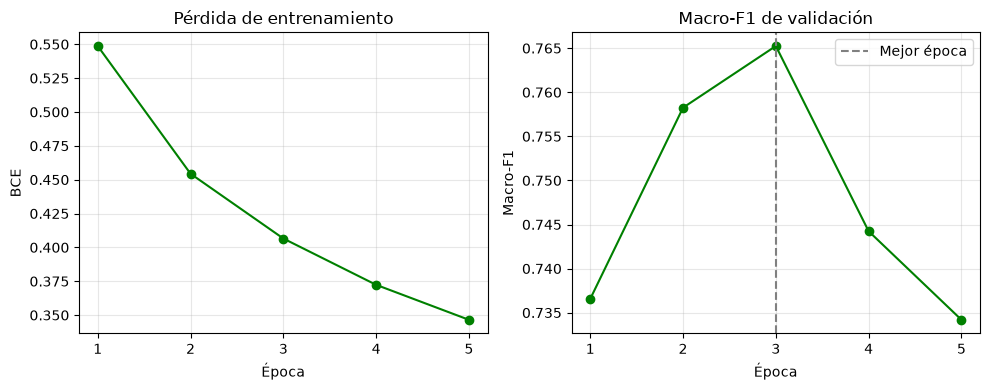

In [ ]:
import matplotlib.pyplot as plt

#Graficamos la pérdida de entrenamiento y el macro-F1 por época
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

ejes[0].plot(
    tabla_historial["epoca"],
    tabla_historial["perdida_train"],
    marker="o",
    color="green"
)
ejes[0].set_title("Pérdida de entrenamiento")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("BCE")

ejes[1].plot(
    tabla_historial["epoca"],
    tabla_historial["macro_f1_valid"],
    marker="o",
    color = "green"
)
ejes[1].axvline(
    mejor_epoca,
    color="gray",
    linestyle="--",
    label="Mejor época",
)
ejes[1].set_title("Macro-F1 de validación")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Macro-F1")
ejes[1].legend()

for eje in ejes:
    eje.set_xticks(tabla_historial["epoca"])
    eje.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#Para recuperar los pesos de la mejor época
pesos = torch.load(
    ruta_checkpoint,
    map_location="cpu",
    weights_only=True,
)

modelo.load_state_dict(pesos)
modelo.eval()

print(f"Modelo restaurado: mejor época de validación ({mejor_epoca})")

Modelo restaurado: mejor época de validación (3)


## Evaluación sobre test

Evaluamos el checkpoint seleccionado por macro-F1 de validación.
Se mantiene un umbral de 0,5 para cada etiqueta.

Vemos precisión, recall y F1 por defecto, además de macro-F1.

In [15]:
from sklearn.metrics import classification_report, f1_score

clases = ["broken", "pollution-flashover"]

y_test = []
pred_test = []
prob_test = []

modelo.eval()

with torch.no_grad():
    for imagenes, etiquetas in loader_test:
        logits = modelo(imagenes)
        probabilidades = torch.sigmoid(logits)
        decisiones = (probabilidades >= 0.5).int()

        y_test.extend(etiquetas.int().tolist())
        pred_test.extend(decisiones.tolist())
        prob_test.extend(probabilidades.tolist())

print("Recortes test:", len(y_test))

print(classification_report(
    y_test,
    pred_test,
    target_names=clases,
    digits=3,
    zero_division=0,
))

macro_f1_test = f1_score(
    y_test,
    pred_test,
    average="macro",
    zero_division=0,
)

print(f"Macro-F1 test: {macro_f1_test:.4f}")

Recortes test: 70
                     precision    recall  f1-score   support

             broken      0.842     0.533     0.653        30
pollution-flashover      0.714     0.806     0.758        31

          micro avg      0.759     0.672     0.713        61
          macro avg      0.778     0.670     0.705        61
       weighted avg      0.777     0.672     0.706        61
        samples avg      0.571     0.579     0.571        61

Macro-F1 test: 0.7053


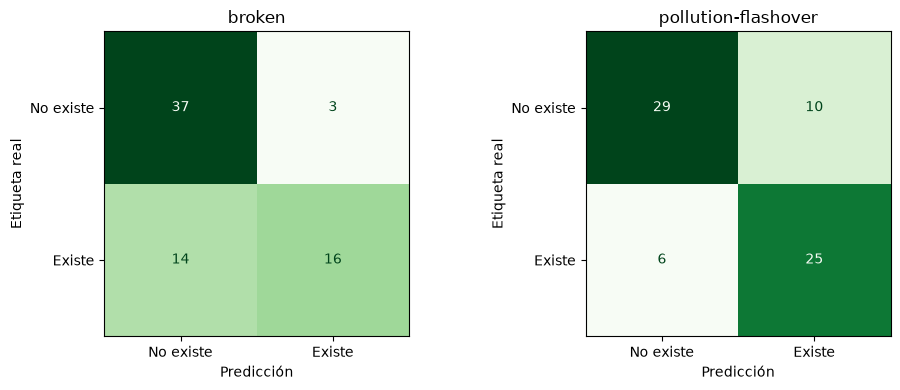

In [ ]:
#Matriz de confusión
from sklearn.metrics import (
    multilabel_confusion_matrix,
    ConfusionMatrixDisplay,
)

matrices = multilabel_confusion_matrix(y_test, pred_test)

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

for indice, eje in enumerate(ejes):
    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matrices[indice],
        display_labels=["No existe", "Existe"],
    )

    visualizacion.plot(
        ax=eje,
        cmap="Greens",
        colorbar=False,
        values_format="d",
    )

    eje.set_title(clases[indice])
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Etiqueta real")

plt.tight_layout()
plt.show()

### Interpretación y limitaciones

El modelo obtuvo macro-F1 de 0,7053 sobre 70 recortes de test,
procedentes de 60 grupos de escenas.

Para rotura, detectó 16 de 30 positivos y omitió 14.
Para contaminación/flashover, detectó 25 de 31 positivos y omitió 6.

Estos resultados permiten presentar un prototipo de apoyo a la revisión
visual, pero el recall de rotura limita su utilidad para descartar defectos.

La evaluación corresponde a recortes del dataset. No demuestra todavía
generalización a infraestructura paraguaya ni detección automática
de aisladores en fotografías completas.